# Lab 5 — The Vision Transformer (ViT)

In Lab 2 and Lab 3 we worked on images with **convolutions**: small filters that slide over the image, looking at
a few neighbouring pixels at a time. In Lab 4 we met the **Transformer**, which works on sequences of tokens and
lets every token look at every other one.

The Vision Transformer ("An image is worth 16x16 words", Dosovitskiy et al., 2020) applies the Transformer to
images with a surprisingly simple idea: **cut the image into patches and treat each patch as a word**.

```
 image ─► cut into patches ─► linear projection ─► + [CLS] token ─► + positions ─► Transformer encoder (× L)
                                                                                       │
                                                    class scores ◄── MLP head ◄── output of [CLS]
```

1. The dataset: CIFAR-10
2. From an image to a sequence of patches
3. Patch embedding
4. The [CLS] token
5. Positional embeddings
6. The Transformer encoder, with PyTorch's blocks
7. The whole model
8. CNN vs ViT: inductive bias and the training recipe
9. A pretrained ViT

Afterwards, in `vit_cifar.py`, you will complete the model and train it.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import models, transforms

from vit_cifar import CIFAR10_CLASSES, DATA_DIR, SmallCNN, ViT, denormalize, get_datasets

torch.manual_seed(0)

# Where CIFAR-10 is downloaded (~150 MB, only the first time): change it if you want
data_dir = DATA_DIR
print("CIFAR-10 folder:", data_dir)

CIFAR-10 folder: C:\Users\dfium\Documents\datasets


---
## 1. The dataset: CIFAR-10

60,000 color images of 32×32 pixels in 10 classes (50,000 for training, 10,000 for testing). Much harder than
MNIST: real photos, with backgrounds, different poses, and very few pixels.

  saved C:\Users\dfium\Documents\datasets\cifar10\train.npz: 50000 images
  saved C:\Users\dfium\Documents\datasets\cifar10\test.npz: 10000 images
train: 50000 images, test: 10000 images
One image: (3, 32, 32) torch.float32 label: 3 cat


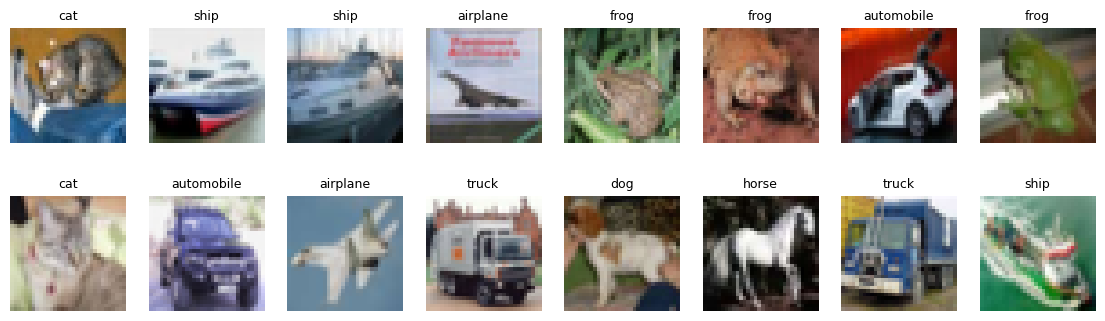

In [2]:
train_set, test_set = get_datasets(data_dir)
print(f"train: {len(train_set)} images, test: {len(test_set)} images")

img, label = test_set[0]
print("One image:", tuple(img.shape), img.dtype, "label:", label, CIFAR10_CLASSES[label])

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    img, label = test_set[i]
    ax.imshow(denormalize(img[None])[0].permute(1, 2, 0))
    ax.set_title(CIFAR10_CLASSES[label], fontsize=9)
    ax.axis("off")
plt.show()

---
## 2. From an image to a sequence of patches

We cut the $32 \times 32$ image into a grid of non-overlapping $p \times p$ patches. With $p = 4$ we get an
$8 \times 8$ grid, i.e. a **sequence of $N = 64$ tokens**. Each patch contains $p \cdot p \cdot 3 = 48$ numbers.

`unfold(dim, size, step)` extracts sliding windows along a dimension: with `size = step = p` the windows do not
overlap.

grid of patches: (3, 8, 8, 4, 4)
sequence of flattened patches: (64, 48)  -> N = 64 tokens of 48 numbers


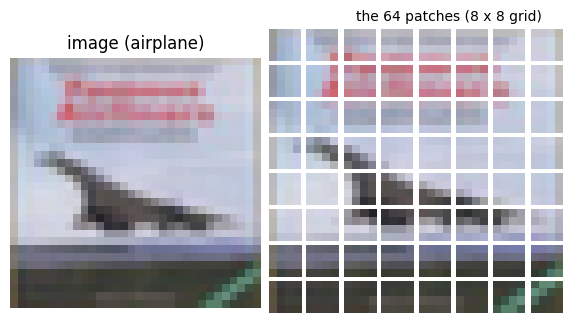

In [3]:
p = 4
img, label = test_set[3]
patches = img.unfold(1, p, p).unfold(2, p, p)          # (C, 8, 8, p, p): an 8x8 grid of 3 x p x p patches
print("grid of patches:", tuple(patches.shape))
patches = patches.permute(1, 2, 0, 3, 4).reshape(-1, 3 * p * p)
print("sequence of flattened patches:", tuple(patches.shape), " -> N = 64 tokens of 48 numbers")

shown = denormalize(img[None])[0]
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(1, 3, 1)
ax.imshow(shown.permute(1, 2, 0))
ax.set_title(f"image ({CIFAR10_CLASSES[label]})")
ax.axis("off")
grid = shown.unfold(1, p, p).unfold(2, p, p)           # (3, 8, 8, p, p)
for r in range(8):
    for c in range(8):
        a = fig.add_axes([0.36 + c * 0.034, 0.8 - r * 0.09, 0.03, 0.08])
        a.imshow(grid[:, r, c].permute(1, 2, 0))
        a.axis("off")
fig.text(0.44, 0.9, "the 64 patches (8 x 8 grid)")
plt.show()

The patch size is a trade-off. Smaller patches give more detail but a longer sequence, and attention costs
$O(N^2)$ (→ Lab 4): every token looks at every other one.

In [4]:
for p_ in [2, 4, 8, 16]:
    n = (32 // p_) ** 2
    print(f"patch {p_:2d}x{p_:<2d} -> N = {n:4d} tokens, {3 * p_ * p_:4d} numbers per patch, "
          f"attention matrix {n:4d} x {n:<4d} = {n * n:8,d} scores")

patch  2x2  -> N =  256 tokens,   12 numbers per patch, attention matrix  256 x 256  =   65,536 scores
patch  4x4  -> N =   64 tokens,   48 numbers per patch, attention matrix   64 x 64   =    4,096 scores
patch  8x8  -> N =   16 tokens,  192 numbers per patch, attention matrix   16 x 16   =      256 scores
patch 16x16 -> N =    4 tokens,  768 numbers per patch, attention matrix    4 x 4    =       16 scores


---
## 3. Patch embedding

Each flattened patch is projected by a **linear layer** to a vector of size $D$ (`dim`), the same for all the
patches: this is the "word embedding" of the ViT.

Nice trick: a `Conv2d` with `kernel_size = stride = p` does *exactly* the same thing. Each output position sees one
patch (no overlap, since the stride equals the kernel), and each of the $D$ filters is a linear combination of its
$3 \cdot p \cdot p$ pixels. Let's verify it by copying the weights of a convolution into a linear layer:

In [7]:
D = 32
conv = nn.Conv2d(3, D, kernel_size=p, stride=p)
linear = nn.Linear(3 * p * p, D)
with torch.no_grad():
    linear.weight.copy_(conv.weight.reshape(D, -1))       # each filter (3, p, p) flattened -> one row of the matrix
    linear.bias.copy_(conv.bias)

out_conv = conv(img[None])                                # (1, D, 8, 8)
out_linear = linear(patches)                              # (64, D)
print("conv output:  ", tuple(out_conv.shape), "  linear output:", tuple(out_linear.shape))
print("Same numbers?", torch.allclose(out_conv[0].flatten(1).T, out_linear, atol=1e-5))

conv output:   (1, 32, 8, 8)   linear output: (64, 32)
Same numbers? True


### The tools for TODO 1
In `vit_cifar.py` the `Conv2d` is already created in `PatchEmbedding.__init__`. Its output is a *grid* $(B, D, 8, 8)$,
but the Transformer wants a *sequence* $(B, N, D)$ (→ Lab 4: batch, length, features). Two operations:

| Operation | Shape |
|---|---|
| `x.flatten(2)` — merges all the dimensions from the 2nd on | $(B, D, 8, 8) \to (B, D, 64)$ |
| `x.transpose(1, 2)` — swaps dimensions 1 and 2 | $(B, D, 64) \to (B, 64, D)$ |

`flatten` reads the grid **row by row**, so token $i$ is the patch in row $i // 8$, column $i \% 8$:

In [8]:
grid = torch.arange(2 * 3 * 8 * 8).reshape(2, 3, 8, 8)       # a fake (B=2, D=3, 8, 8) output with readable values
print("flatten(2):", tuple(grid.flatten(2).shape))
print("then transpose(1, 2):", tuple(grid.flatten(2).transpose(1, 2).shape))
print("\nchannel 0 of the grid, first 2 rows:", grid[0, 0, :2].tolist())
print("channel 0 after flatten, first 16 tokens:", grid[0, 0].flatten().tolist()[:16])

flatten(2): (2, 3, 64)
then transpose(1, 2): (2, 64, 3)

channel 0 of the grid, first 2 rows: [[0, 1, 2, 3, 4, 5, 6, 7], [8, 9, 10, 11, 12, 13, 14, 15]]
channel 0 after flatten, first 16 tokens: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


---
## 4. The [CLS] token

To classify the image we need **one vector** for the whole image. The ViT borrows an idea from BERT: it adds to the
sequence an extra, **learned** token, `[CLS]`, which is not a patch. Through attention, in every layer the `[CLS]`
token collects information from all the patches; at the end, its output is the representation of the image, and
a linear head turns it into class scores.

(An alternative is to average the outputs of all the patches, "global average pooling", as in the CNN of Lab 2.)

In the model, `[CLS]` is an `nn.Parameter` of shape $(1, 1, D)$: *one* vector, shared by all the images. For a batch
we must repeat it $B$ times and put it **in front** of the patches.

### The tools for TODO 2

| Operation | Shape |
|---|---|
| `cls.expand(B, -1, -1)` — repeats along the dimensions of size 1 (`-1` = keep that size), without copying memory | $(1, 1, D) \to (B, 1, D)$ |
| `torch.cat([a, b], dim=1)` — concatenates along the sequence dimension | $(B, 1, D) + (B, N, D) \to (B, N+1, D)$ |

In [9]:
B, N = 4, 64
cls_token = nn.Parameter(torch.randn(1, 1, D))
patch_tokens = torch.randn(B, N, D)

cls_batch = cls_token.expand(B, -1, -1)
print("cls:", tuple(cls_token.shape), " -> expand:", tuple(cls_batch.shape))
print("the same vector for every image?", torch.equal(cls_batch[0], cls_batch[3]))

sequence = torch.cat([cls_batch, patch_tokens], dim=1)
print("cat:", tuple(cls_batch.shape), "+", tuple(patch_tokens.shape), "->", tuple(sequence.shape))
print("position 0 is the [CLS] token?", torch.equal(sequence[:, 0], cls_batch[:, 0]))

cls: (1, 1, 32)  -> expand: (4, 1, 32)
the same vector for every image? True
cat: (4, 1, 32) + (4, 64, 32) -> (4, 65, 32)
position 0 is the [CLS] token? True


---
## 5. Positional embeddings

As we saw in Lab 4 (§2), attention does not know the order of the tokens: without positions, a ViT would see a
**bag of patches**, and a shuffled image would give the same prediction as the original one!

In Lab 4 we **added** fixed sinusoidal encodings. The ViT uses **learned** positional embeddings instead: an
`nn.Parameter` of shape $(1, N + 1, D)$, one vector per position (including `[CLS]`), trained together with the rest
of the network. They are added to the tokens with broadcasting over the batch (→ tensors §9):

In [10]:
pos_embed = nn.Parameter(torch.zeros(1, N + 1, D))
nn.init.trunc_normal_(pos_embed, std=0.02)                 # small random values at the beginning
tokens = sequence + pos_embed                              # (B, N+1, D) + (1, N+1, D)
print(f"{tuple(sequence.shape)} + {tuple(pos_embed.shape)} -> {tuple(tokens.shape)}")

(4, 65, 32) + (1, 65, 32) -> (4, 65, 32)


They start random: nobody tells the model that the patches lie on a 2D grid. After training, you will see (the
script plots it at the end) that each position becomes **similar to its neighbours**: the model learns the 2D
structure of the image by itself.

---
## 6. The Transformer encoder, with PyTorch's blocks

In Lab 4 you wrote the encoder block yourself. Here we use PyTorch's `nn.TransformerEncoderLayer`, with two
differences from the original Transformer, as in the ViT paper:

- **pre-norm**: the LayerNorm goes *before* each sub-layer, and the residual path stays "clean". It trains more
  stably, especially with many layers (`norm_first=True`):

$$\text{post-norm (Lab 4)}: \; x \leftarrow \text{LN}\big(x + \text{sublayer}(x)\big) \qquad
  \text{pre-norm (ViT)}: \; x \leftarrow x + \text{sublayer}\big(\text{LN}(x)\big)$$

- **GELU** instead of ReLU in the feed-forward network (`activation="gelu"`): a smooth version of ReLU.

`nn.TransformerEncoder` stacks `num_layers` copies of the block. Don't forget `batch_first=True` (→ Lab 2)!

In [11]:
layer = nn.TransformerEncoderLayer(d_model=D, nhead=4, dim_feedforward=64, dropout=0.1,
                                   activation="gelu", batch_first=True, norm_first=True)
encoder = nn.TransformerEncoder(layer, num_layers=3, enable_nested_tensor=False)
print(layer)

out = encoder(tokens)
print("\nencoder:", tuple(tokens.shape), "->", tuple(out.shape), " (the shape never changes)")

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
  )
  (linear1): Linear(in_features=32, out_features=64, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=64, out_features=32, bias=True)
  (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

encoder: (4, 65, 32) -> (4, 65, 32)  (the shape never changes)


### The tools for TODO 3
After the encoder we only need the output of the `[CLS]` token, which is at **position 0** of the sequence. Indexing
with `x[:, 0]` takes position 0 of every sequence of the batch (and removes that dimension):

In [12]:
cls_out = out[:, 0]
print("encoder output:", tuple(out.shape), " -> out[:, 0]:", tuple(cls_out.shape))
head = nn.Linear(D, 10)
print("-> head:", tuple(head(nn.LayerNorm(D)(cls_out)).shape), " (B, n_classes)")

encoder output: (4, 65, 32)  -> out[:, 0]: (4, 32)
-> head: (4, 10)  (B, n_classes)


---
## 7. The whole model

In `vit_cifar.py` all the layers are **already created** in `ViT.__init__` (and the `Conv2d` in
`PatchEmbedding.__init__`); your job is to write how the data flows through them:

| TODO | Method | From | To |
|---|---|---|---|
| 1 | `PatchEmbedding.forward(x)` | images $(B, 3, 32, 32)$ | patch embeddings $(B, N, D)$ |
| 2 | `ViT.embed(images)` | images $(B, 3, 32, 32)$ | `[CLS]` + patches + positions $(B, N+1, D)$ |
| 3 | `ViT.forward(images)` | images $(B, 3, 32, 32)$ | class scores $(B, 10)$ |

and these are the attributes you will use:

In [13]:
vit = ViT()
for name, module in vit.named_children():
    n = sum(p.numel() for p in module.parameters())
    print(f"self.{name:12s} {module.__class__.__name__:20s} {n:>10,} parameters")
print(f"self.{'cls_token':12s} {'nn.Parameter':20s} {vit.cls_token.numel():>10,} parameters   shape {tuple(vit.cls_token.shape)}")
print(f"self.{'pos_embed':12s} {'nn.Parameter':20s} {vit.pos_embed.numel():>10,} parameters   shape {tuple(vit.pos_embed.shape)}")
print(f"\nTotal ViT: {sum(p.numel() for p in vit.parameters()):,} parameters")
print(f"Total SmallCNN (for comparison): {sum(p.numel() for p in SmallCNN().parameters()):,} parameters")

self.patch_embed  PatchEmbedding            9,408 parameters
self.dropout      Dropout                       0 parameters
self.encoder      TransformerEncoder    1,782,144 parameters
self.norm         LayerNorm                   384 parameters
self.head         Linear                    1,930 parameters
self.cls_token    nn.Parameter                192 parameters   shape (1, 1, 192)
self.pos_embed    nn.Parameter             12,480 parameters   shape (1, 65, 192)

Total ViT: 1,806,538 parameters
Total SmallCNN (for comparison): 1,149,770 parameters


---
## 8. CNN vs ViT: inductive bias and the training recipe

A CNN has strong assumptions built in (**inductive bias**): each filter looks only at a small neighbourhood
(*locality*) and the same filter is used everywhere (*translation equivariance*, → Lab 2). The ViT has almost none:
from the very first layer every patch can look at every other patch, and even the 2D structure of the image must
be learned (§5).

- **Pro**: it is more flexible, and it captures long-range relations from the first layer.
- **Con**: it must learn from the data what a CNN knows from the start. On small datasets such as CIFAR-10, trained
  from scratch, a ViT usually does **not** beat a good CNN. ViTs shine when they are **pretrained on huge datasets**
  (ImageNet-21k, JFT-300M: tens or hundreds of millions of images) and then fine-tuned (→ Lab 3, pretrained weights).

With `python vit_cifar.py --model cnn` the script trains the small CNN of Lab 2 with exactly the same recipe:
compare the two!

To train a ViT from scratch the recipe matters a lot. The script uses:

| Ingredient | Why |
|---|---|
| data augmentation (random crop + flip) | more "different" images: fights overfitting, which ViTs are prone to |
| AdamW + weight decay 0.05 | the standard optimizer for Transformers, with regularization |
| warmup + cosine decay (OneCycle) | Transformers are sensitive to large learning rates at the beginning (→ Lab 4) |
| label smoothing 0.1 | targets 0.9 / 0.01 instead of 1 / 0: the model is not pushed to be over-confident |
| gradient clipping | avoids rare huge updates |

---
## 9. A pretrained ViT

To see what a *well-trained* ViT can do, let's load **ViT-B/16** from `torchvision`: 86 million parameters,
$16 \times 16$ patches on $224 \times 224$ images (so $N = 196$ tokens), pretrained on ImageNet
(⚠️ ~330 MB download the first time). Our 32×32 CIFAR images are upscaled to 224×224.

In [14]:
weights = models.ViT_B_16_Weights.DEFAULT
vit_b16 = models.vit_b_16(weights=weights).eval()
preprocess = weights.transforms()
print(f"ViT-B/16: {sum(p.numel() for p in vit_b16.parameters()):,} parameters")
print("Preprocessing:", preprocess)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\dfium/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [01:50<00:00, 3.14MB/s] 


ViT-B/16: 86,567,656 parameters
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


Let's ask it what it sees in some CIFAR-10 test images. It predicts one of the **1000 ImageNet classes**, which are
much more specific than the 10 of CIFAR (e.g. "fire engine" instead of "truck", dog breeds instead of "dog"):

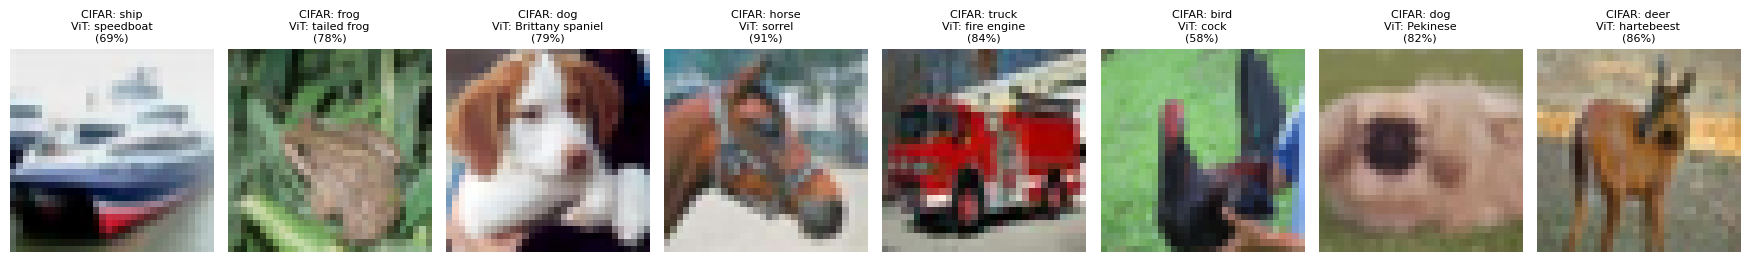

In [15]:
to_pil = transforms.ToPILImage()
idx = [1, 4, 16, 17, 23, 25, 31, 36]
raw = [denormalize(test_set[i][0][None])[0] for i in idx]              # back to [0, 1] images
batch = torch.stack([preprocess(to_pil(r)) for r in raw])              # resize to 224, ImageNet normalization
with torch.no_grad():
    probs = vit_b16(batch).softmax(-1)

fig, axes = plt.subplots(1, len(idx), figsize=(2.2 * len(idx), 2.8))
for j, i in enumerate(idx):
    top = probs[j].argmax().item()
    axes[j].imshow(raw[j].permute(1, 2, 0))
    axes[j].set_title(f"CIFAR: {CIFAR10_CLASSES[test_set[i][1]]}\nViT: {weights.meta['categories'][top]}\n"
                      f"({100 * probs[j, top]:.0f}%)", fontsize=8)
    axes[j].axis("off")
plt.tight_layout()
plt.show()

Not bad for images that were never seen at this resolution: a 32×32 image upscaled to 224×224 is very blurry, and
the model was trained on sharp photos (on some of the other CIFAR images it makes funny mistakes: try changing
`idx`!).

💡 **Going further**: to *fine-tune* it on CIFAR-10 it is enough to replace the final head,
`vit_b16.heads = nn.Linear(768, 10)`, and train with a small learning rate. Fine-tuned pretrained ViTs reach
about 97–99% on CIFAR-10, far beyond what a ViT trained from scratch on 50,000 images can do. That's the power of
pretraining.

---
## Summary

| Piece | What it does | Shape |
|---|---|---|
| patches | cut the image into a grid of $p \times p$ patches | $(B, 3, H, W) \to N = (H/p)(W/p)$ patches |
| patch embedding | `Conv2d(k = s = p)` + `flatten(2)` + `transpose(1, 2)` | $(B, N, D)$ |
| `[CLS]` token | learned vector, `expand` to the batch, `cat` in front | $(B, N+1, D)$ |
| positional embeddings | learned, added with broadcasting | $(1, N+1, D)$ |
| Transformer encoder | `nn.TransformerEncoder` (pre-norm, GELU) | $(B, N+1, D)$ |
| classification | `x[:, 0]` → LayerNorm → Linear | $(B, n_{classes})$ |

👉 **Now it's your turn:** open `vit_cifar.py` and complete the three TODOs. The script checks each of them before
training; at the end it shows the similarity of the learned positional embeddings and where the `[CLS]` token of
your model looks (the attention of the last layer: take it with a grain of salt, attention maps are only a rough
indication of what a model "looks at").